# Is Healthy Eating a Luxury? 
### A reproducible analysis of healthy diet costs and affordability (2017–2025)

**Research questions:** (1) Where is healthy eating a luxury? (2) Does wealth guarantee affordability? (3) How have cost and affordability changed over time? (4) What is behind the price of a healthy diet? (5) Can we predict affordability? (6) Can we identify countries with similar socioeconomic characteristics?

**Data sources:** FAOSTAT Cost and Affordability of a Healthy Diet and World Bank indicators. The original FAOSTAT Excel workbook and World Bank CSV files must be downloaded manually from their official sources before running the notebook. All tables, figures and models are then generated from these files. 

**How to use:** Keep this notebook in the project root, the seven Python modules in `scipts/`, the FAOSTAT workbook in `data/`, and the original World Bank CSV files in `data/world_bank/`. Select the project's Python environment and run **Run All**. Figures and tables are also saved in `outputs/`.

## 0. Environment and reproducibility
The scripts are imported as libraries. Their names start with numbers, so we load them using `importlib`. Importing a module does **not** execute the data pipeline.

In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
import numpy as np
from IPython.display import display, HTML, Image, IFrame

ROOT = Path.cwd().resolve()
if not (ROOT / 'scipts').is_dir():
    raise FileNotFoundError('Open Jupyter from the project root: expected the scipts/ folder.')
SCRIPTS = ROOT / 'scipts'

def load_module(alias, filename):
    path = SCRIPTS / filename
    if not path.is_file():
        raise FileNotFoundError(f'Missing module: {path}. Rename the supplied *_modulo.py file to {filename}.')
    spec = importlib.util.spec_from_file_location(alias, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

cleaning = load_module('cleaning', '01_data_cleaning.py')
integration = load_module('integration', '02_data_integration.py')
eda = load_module('eda', '03_eda.py')
dashboard = load_module('dashboard', '03_eda_dashboard.py')
preprocessing = load_module('preprocessing', '04_preprocessing.py')
unsup = load_module('unsup', '05_unsupervised.py')
sup = load_module('sup', '06_supervised.py')

print('Project root:', ROOT)
print('All seven modules imported successfully.')

Project root: /Users/giorgia/Desktop/healthy_eating_analisys
All seven modules imported successfully.


In [2]:
# Verify original inputs before starting.
faostat_file = ROOT / 'data' / 'FAOSTAT_data_en_11-3-2026.xlsx'
world_bank_files = sorted((ROOT / 'data' / 'world_bank').glob('API_*.csv'))
assert faostat_file.is_file(), f'Missing FAOSTAT file: {faostat_file}'
assert len(world_bank_files) >= len(integration.WORLD_BANK_INDICATORS), 'Missing World Bank CSV files.'
print('FAOSTAT:', faostat_file.name)
print('World Bank CSV files:', len(world_bank_files))

FAOSTAT: FAOSTAT_data_en_11-3-2026.xlsx
World Bank CSV files: 8


## 1. Data cleaning — FAOSTAT

We start from the original Excel workbook. We keep the required fields, remove the aggregate **China** area while retaining mainland China, keep PPP-denominated food-cost indicators, and exclude alternative simple/weighted-average indicators. We convert years and values to numeric types. **Missing values are not automatically imputed.**

In [3]:
faostat_raw = cleaning.load_faostat_data(faostat_file)
print('Raw shape:', faostat_raw.shape)
display(faostat_raw.head())
faostat_clean = cleaning.clean_faostat_data(faostat_raw)
print('Cleaned shape:', faostat_clean.shape)
display(pd.Series(cleaning.summarize_faostat_data(faostat_clean), name='Value').to_frame())
display(cleaning.build_indicator_coverage(faostat_clean))
cleaning.save_cleaned_data(faostat_clean)

Raw shape: (8400, 15)


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code,Item,Year Code,Year,Release,Unit,Value,Flag,Flag Description
0,CAHD,Cost and Affordability of a Healthy Diet (CoAHD),8,Albania,6226,Value,70040,Cost of a healthy diet (CoHD),2017,2017,July 2026 (SOFI report),Int$ (PPP) per person per day,3.04,E,Estimated value
1,CAHD,Cost and Affordability of a Healthy Diet (CoAHD),8,Albania,6226,Value,70040,Cost of a healthy diet (CoHD),2018,2018,July 2026 (SOFI report),Int$ (PPP) per person per day,3.13,E,Estimated value
2,CAHD,Cost and Affordability of a Healthy Diet (CoAHD),8,Albania,6226,Value,70040,Cost of a healthy diet (CoHD),2019,2019,July 2026 (SOFI report),Int$ (PPP) per person per day,3.32,E,Estimated value
3,CAHD,Cost and Affordability of a Healthy Diet (CoAHD),8,Albania,6226,Value,70040,Cost of a healthy diet (CoHD),2020,2020,July 2026 (SOFI report),Int$ (PPP) per person per day,3.40,E,Estimated value
4,CAHD,Cost and Affordability of a Healthy Diet (CoAHD),8,Albania,6226,Value,70040,Cost of a healthy diet (CoHD),2021,2021,July 2026 (SOFI report),Int$ (PPP) per person per day,3.49,E,Estimated value


Cleaned shape: (5742, 6)


,Value
rows,5742
countries_or_areas,174
first_year,2017
last_year,2025
indicators,9
missing_values,636
available_m49,5742


,Indicator,Unit,rows,available
0,Cost of a healthy diet (CoHD),Int$ (PPP) per person per day,1566,1492
1,Cost of animal source foods,Int$ (PPP) per person per day,174,162
2,Cost of fruits,Int$ (PPP) per person per day,174,162
3,"Cost of legumes, nuts and seeds",Int$ (PPP) per person per day,174,162
4,Cost of oils and fats,Int$ (PPP) per person per day,174,162
5,Cost of starchy staples,Int$ (PPP) per person per day,174,162
6,Cost of vegetables,Int$ (PPP) per person per day,174,162
7,Number of people unable to afford a healthy di...,million No,1566,1321
8,Prevalence of unaffordability (PUA),%,1566,1321


PosixPath('/Users/giorgia/Desktop/healthy_eating_analisys/data/processed/faostat_clean.csv')

## 2. Data integration — FAOSTAT and World Bank

FAOSTAT is converted to one row per **country–year**, with CoHD (cost), PUA (percentage unable to afford), and NUA (number unable to afford). The six food categories are prepared separately for **2021**. World Bank files are reshaped from wide to long format for 2017–2025; aggregate economies are excluded. Countries are matched by normalized names and verified ISO3 overrides. We then merge by ISO3 and year, derive population density, and attach continent labels.

For 2025, missing surface area is filled from the same country's 2024 value **only when available**; this is a specific rule from the integration script, not a general imputation strategy.

In [4]:
faostat_longitudinal = integration.prepare_longitudinal_faostat(faostat_clean)
food_categories = integration.prepare_food_categories(faostat_clean)
world_bank, excluded_aggregates = integration.load_world_bank_data(ROOT / 'data' / 'world_bank')
print('FAOSTAT country-year records:', len(faostat_longitudinal))
print('2021 food-category countries:', len(food_categories))
print('World Bank aggregate economies excluded:', excluded_aggregates)
display(faostat_longitudinal.head())
display(food_categories.head())
display(world_bank.head())

FAOSTAT country-year records: 1566
2021 food-category countries: 174
World Bank aggregate economies excluded: 50


,Country,Year,CoHD,NUA,PUA
0,Albania,2017,3.04,0.8,29.2
1,Albania,2018,3.13,0.6,20.9
2,Albania,2019,3.32,0.5,18.4
3,Albania,2020,3.40,0.5,17.6
4,Albania,2021,3.49,0.5,16.0


,Country,Animal_Foods,Fruits,Legumes_Nuts_Seeds,Oils_Fats,Starchy_Staples,Vegetables
0,Albania,1.13,0.77,0.41,0.11,0.47,0.60
1,Algeria,1.36,1.10,0.58,0.15,0.56,0.72
2,Angola,1.15,0.75,0.42,0.21,1.15,0.44
3,Antigua and Barbuda,0.80,1.59,0.48,0.13,0.67,1.26
4,Argentina,NaN,NaN,NaN,NaN,NaN,NaN


,Country Name,Country Code,Year,GDP_PPP,Gini,Poverty,Inflation,Unemployment,Urban,Population,Surface_km2
0,Aruba,ABW,2017,37524.914920,NaN,NaN,-1.028282,NaN,62.776849,108735.0,180.0
1,Aruba,ABW,2018,39287.059713,NaN,NaN,3.626041,NaN,62.536764,108908.0,180.0
2,Aruba,ABW,2019,38554.716783,NaN,NaN,4.257462,NaN,62.288276,109203.0,180.0
3,Aruba,ABW,2020,28733.604511,NaN,NaN,NaN,NaN,62.002884,108587.0,180.0
4,Aruba,ABW,2021,35207.170909,NaN,NaN,NaN,NaN,61.927534,107700.0,180.0


In [5]:
matched, matching_report = integration.match_faostat_countries(faostat_longitudinal, world_bank)
print('Automatically matched countries:', matching_report['automatically_matched_countries'])
print('Finally matched countries:', matching_report['finally_matched_countries'])
print('Unmatched countries:')
display(matching_report['unmatched_countries'].to_frame(name='Country'))
combined, filled_count = integration.integrate_country_year_data(matched, world_bank)
panel = integration.build_panel(combined)
food_2021 = integration.build_food_dataset(panel, food_categories)
print('2025 surface values filled from 2024:', filled_count)
print('Panel:', panel.shape, '| Countries:', panel.ISO3.nunique())
print('Food 2021:', food_2021.shape)
display(panel.head())
display(food_2021.head())
integration.save_integrated_datasets(panel, food_2021)

Automatically matched countries: 147
Finally matched countries: 173
Unmatched countries:


,Country
333,"China, Taiwan Province of"


2025 surface values filled from 2024: 171
Panel: (1557, 16) | Countries: 173
Food 2021: (173, 21)


,ISO3,Country,Year,CoHD,PUA,NUA,GDP_PPP,Gini,Poverty,Inflation,Unemployment,Urban,Population,Surface_km2,Population_Density,Continent
0,ALB,Albania,2017,3.04,29.2,0.8,14110.672057,33.1,1.4,1.986661,13.616,55.980276,2648285.0,28750.0,92.114261,Europe
1,ALB,Albania,2018,3.13,20.9,0.6,15055.347382,30.1,1.0,2.028060,12.304,56.377000,2607733.0,28750.0,90.703757,Europe
2,ALB,Albania,2019,3.32,18.4,0.5,16442.025475,30.1,0.3,1.411091,11.466,56.763907,2567801.0,28750.0,89.314817,Europe
3,ALB,Albania,2020,3.40,17.6,0.5,16287.613673,29.4,0.3,1.620887,11.639,57.140859,2528480.0,28750.0,87.947130,Europe
4,ALB,Albania,2021,3.49,16.0,0.5,18212.794718,NaN,NaN,2.041472,11.474,57.507719,2489762.0,28750.0,86.600417,Europe


,ISO3,Country,Continent,Animal_Foods,Fruits,Legumes_Nuts_Seeds,Oils_Fats,Starchy_Staples,Vegetables,CoHD,...,NUA,GDP_PPP,Gini,Poverty,Inflation,Unemployment,Urban,Population,Surface_km2,Population_Density
0,ALB,Albania,Europe,1.13,0.77,0.41,0.11,0.47,0.60,3.49,...,0.5,18212.794718,NaN,NaN,2.041472,11.474,57.507719,2489762.0,28750.0,86.600417
1,DZA,Algeria,Africa,1.36,1.10,0.58,0.15,0.56,0.72,4.47,...,19.2,14496.865470,NaN,NaN,7.226063,13.656,73.619922,44761099.0,2381740.0,18.793445
2,AGO,Angola,Africa,1.15,0.75,0.42,0.21,1.15,0.44,4.11,...,24.5,8720.187687,NaN,NaN,25.754295,15.799,68.252416,34532429.0,1246700.0,27.699069
3,ATG,Antigua and Barbuda,North America,0.80,1.59,0.48,0.13,0.67,1.26,4.92,...,NaN,25745.495807,NaN,NaN,2.062996,NaN,24.574984,92349.0,440.0,209.884091
4,ARG,Argentina,South America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,26300.274261,42.4,1.4,48.409379,8.736,92.029278,45312281.0,2780400.0,16.297037


{'panel': PosixPath('/Users/giorgia/Desktop/healthy_eating_analisys/data/processed/panel_data.csv'),
 'food_2021': PosixPath('/Users/giorgia/Desktop/healthy_eating_analisys/data/processed/food_categories_2021.csv')}

### Data availability

The panel retains incomplete country-year observations for descriptive analysis. The number of available observations differs across indicators and years. The food dataset is cross-sectional because comparable category costs are used for 2021.

In [6]:
display(panel.groupby('Year')[['CoHD','PUA','NUA','GDP_PPP','Urban','Unemployment','Inflation']].count())
display(panel.groupby('Continent')['ISO3'].nunique().sort_values(ascending=False).to_frame('Countries'))

,CoHD,PUA,NUA,GDP_PPP,Urban,Unemployment,Inflation
Year,,,,,,,
2017,165,146,146,171,173,162,166
2018,165,146,146,171,173,162,166
2019,165,146,146,171,173,162,166
2020,165,146,146,171,173,162,162
2021,165,146,146,171,173,162,162
2022,165,146,146,171,173,162,162
2023,165,146,146,170,173,160,160
2024,164,145,145,170,173,158,159
2025,164,145,145,162,173,158,153


,Countries
Continent,
Africa,52
Asia,43
Europe,38
North America,26
South America,11
Oceania,3


## 3. Interactive dashboard

The dashboard combines geographic views, country trends, socioeconomic relationships and food-category comparisons. It includes year and continent filters, consistent continent colors, and world/continent averages where implemented. The HTML is generated **directly from `panel` and `food_2021`**.

In [7]:
dashboard_path = Path(dashboard.build_dashboard(panel_data=panel, food_data=food_2021)).resolve()
print('Dashboard saved:', dashboard_path)
display(HTML(f'<a href="{dashboard_path.as_uri()}" target="_blank">Open the full interactive dashboard</a>'))
# If your notebook environment allows local-file iframes, uncomment:
# display(IFrame(src=dashboard_path.as_uri(), width='100%', height=750))

Observations: 1557
Countries: 173
Years: 2017–2025

Data availability by year:
      CoHD  PUA
Year           
2017   165  146
2018   165  146
2019   165  146
2020   165  146
2021   165  146
2022   165  146
2023   165  146
2024   164  145
2025   164  145

Descriptive statistics:
          CoHD      PUA
count  1483.00  1312.00
mean      3.79    35.09
std       0.98    27.29
min       1.70     0.10
25%       3.08     9.40
50%       3.65    29.35
75%       4.39    56.62
max       8.27    95.80
Countries with complete series CoHD: 164
Countries with complete series PUA: 145

Interactive dashboard saved to: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/dashboard/healthy_diet_dashboard.html
Dashboard saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/dashboard/healthy_diet_dashboard.html


## 4. Exploratory data analysis

The following figures reproduce the original EDA scripts. Country colors identify continents. Interactive choropleths are saved as HTML; static plots are saved as PNG and displayed below. Descriptive relationships should not be interpreted as causal effects.

In [8]:
eda.set_notebook_display(True)
df = eda.load_panel_data(panel)
data_2025 = df.loc[df['Year'].eq(2025)].copy()
print('2025 observations:', len(data_2025))

def show_saved_figure(filename, folder='figures', width=850):
    path = ROOT / 'outputs' / '02_eda' / folder / filename
    if path.is_file():
        display(Image(filename=str(path), width=width))
    else:
        print('Figure not found:', path)

def show_saved_html(filename, folder='maps', height=540):
    path = ROOT / 'outputs' / '02_eda' / folder / filename
    if path.is_file():
        display(HTML(f'<a href="{path.as_uri()}" target="_blank">Open interactive chart: {filename}</a>'))
        display(IFrame(src=path.as_uri(), width='100%', height=height))
    else:
        print('HTML not found:', path)

2025 observations: 173


### RQ1. Where is healthy eating a luxury?
We compare **PUA** (affordability) and **CoHD** (daily PPP cost) geographically, then examine differences between continents using boxplots.

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/maps/1.1_world_pua_2025.html


Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/maps/1.2_world_cohd_2025.html


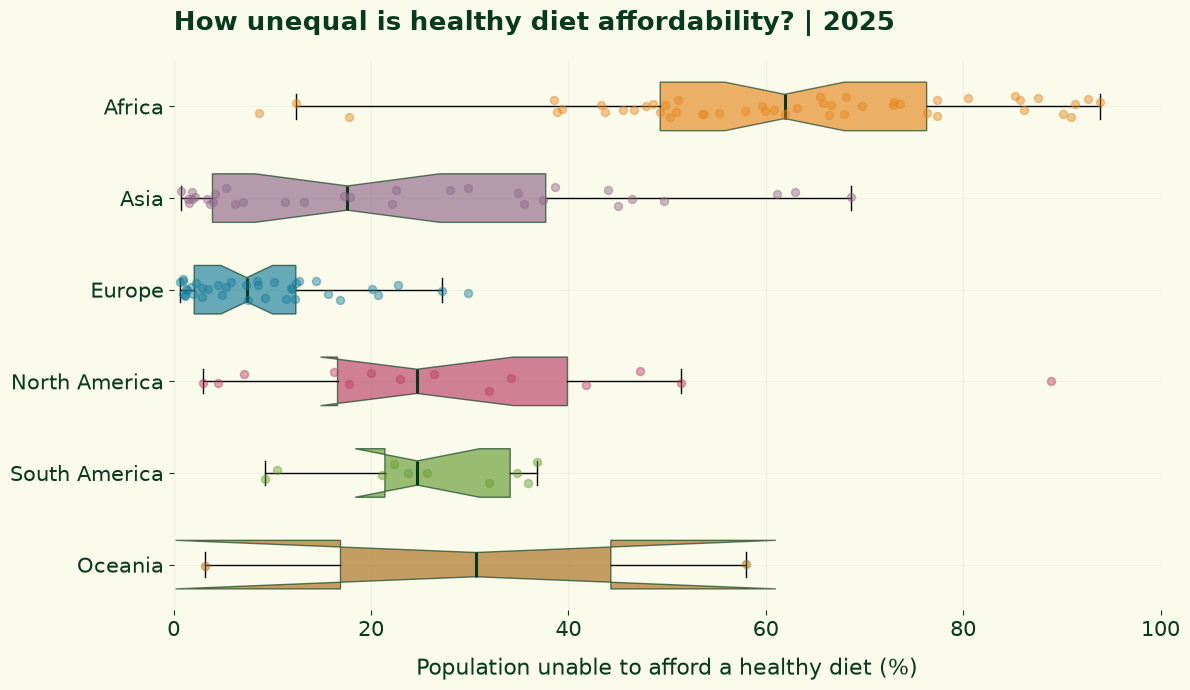

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/1.3_pua_distribution_by_continent_2025.png


In [9]:
eda.plot_world_choropleth(data_2025, 'PUA', '1.1_world_pua_2025.html', 'Where is healthy eating a luxury? | 2025')
show_saved_html('1.1_world_pua_2025.html')
eda.plot_world_choropleth(data_2025, 'CoHD', '1.2_world_cohd_2025.html', 'Where is a healthy diet most expensive? | 2025')
show_saved_html('1.2_world_cohd_2025.html')
eda.plot_continent_affordability_boxplots(data_2025)

### RQ2. Does wealth guarantee affordability?
We study the association between income and PUA, the affordability gap across unemployment groups, and the relationship between inflation and affordability. A log GDP scale helps compare countries with very different income levels.

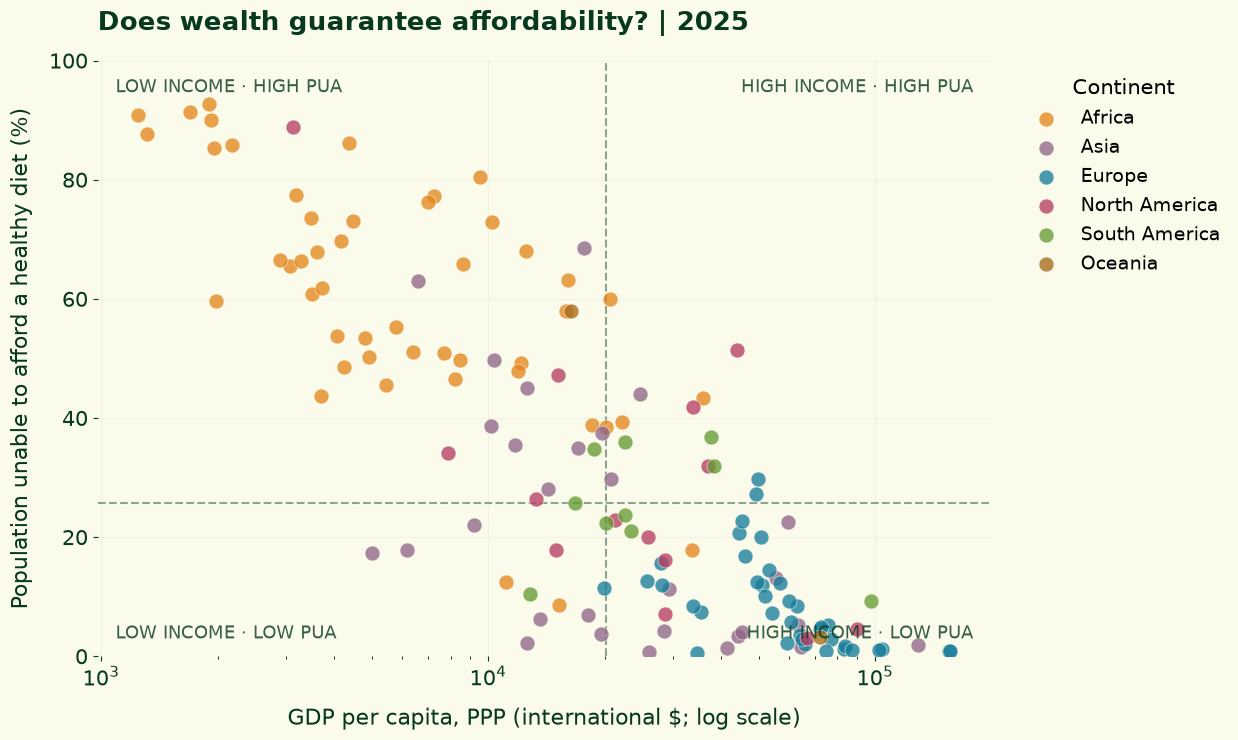

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/2.1_wealth_vs_affordability_quadrants_2025.png


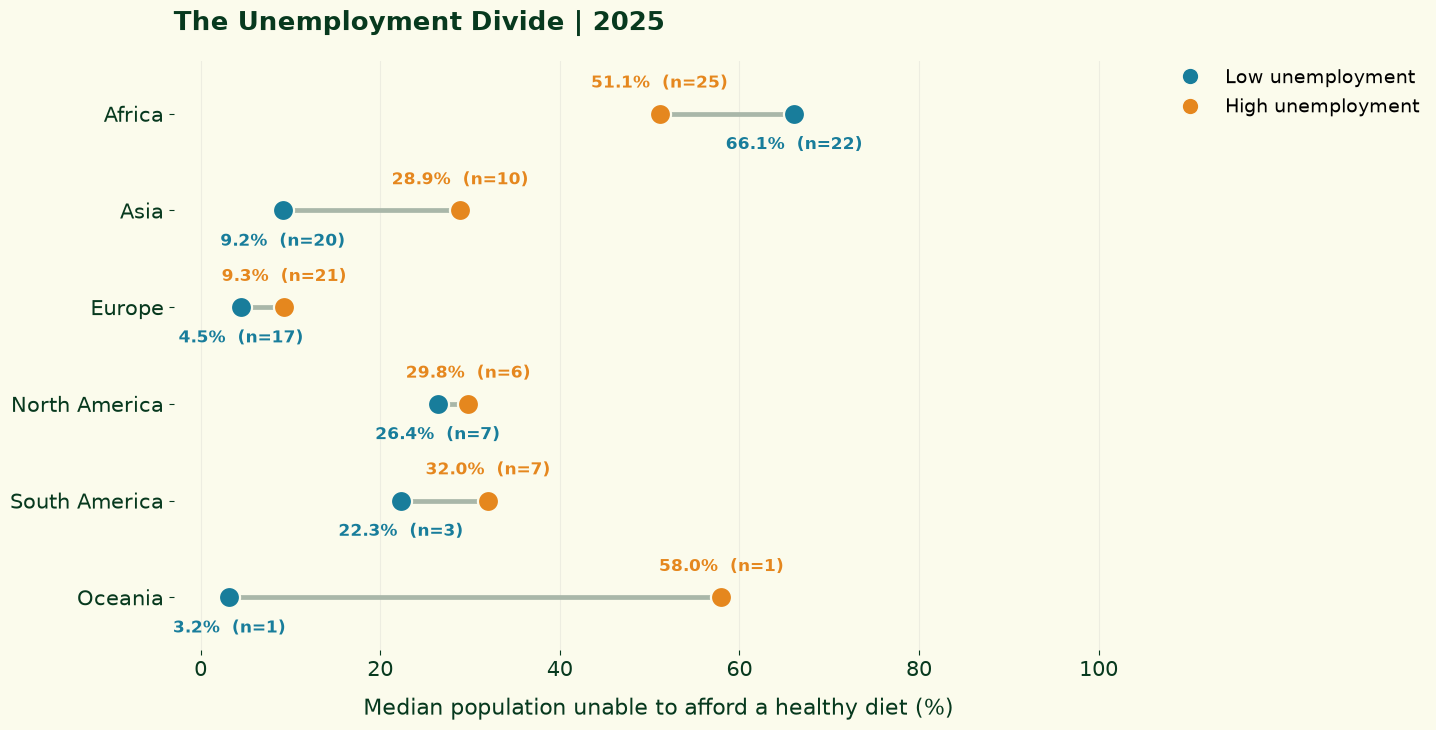

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/2.2_unemployment_divide_2025.png
2.2: 6 continents with both groups; threshold = 5.10%.


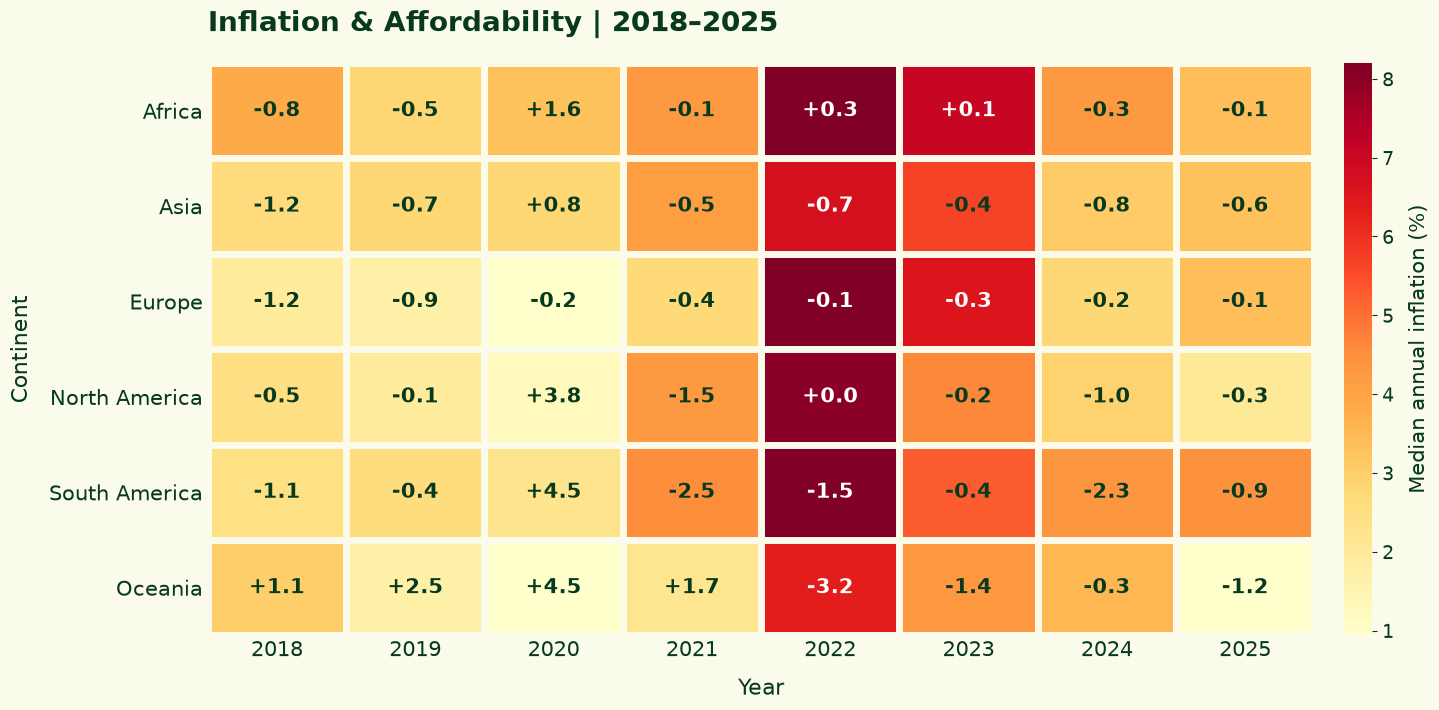

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/2.3_inflation_affordability_heatmap_2018_2025.png


In [10]:
eda.plot_gdp_vs_affordability(data_2025)
eda.plot_unemployment_affordability_gap(data_2025)
eda.plot_inflation_affordability_heatmap(df)

### RQ3. How have cost and affordability changed over time?
Country-year observations from 2017–2025 are aggregated by continent to show trends in PUA and CoHD. Changes in costs and affordability are then compared.

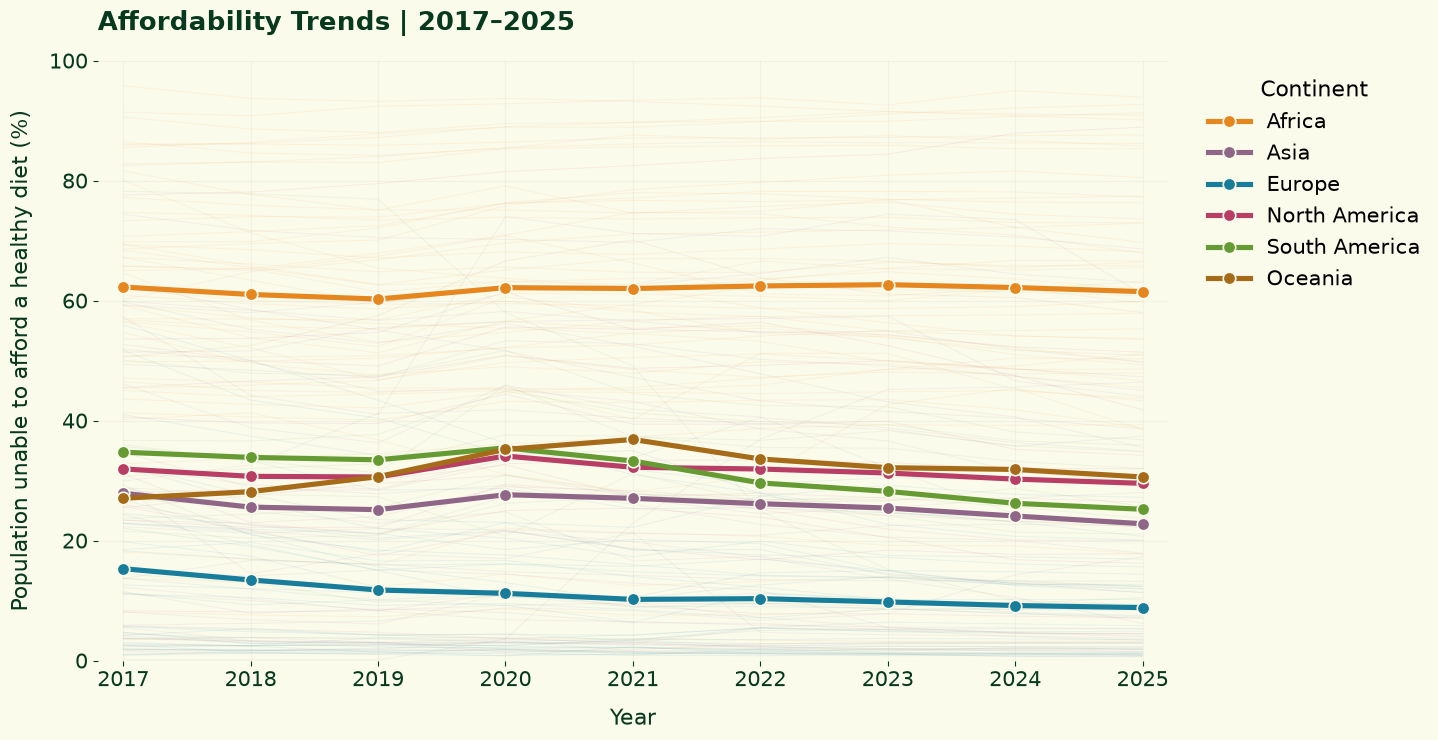

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/3.1_continent_pua_trends_2017_2025.png


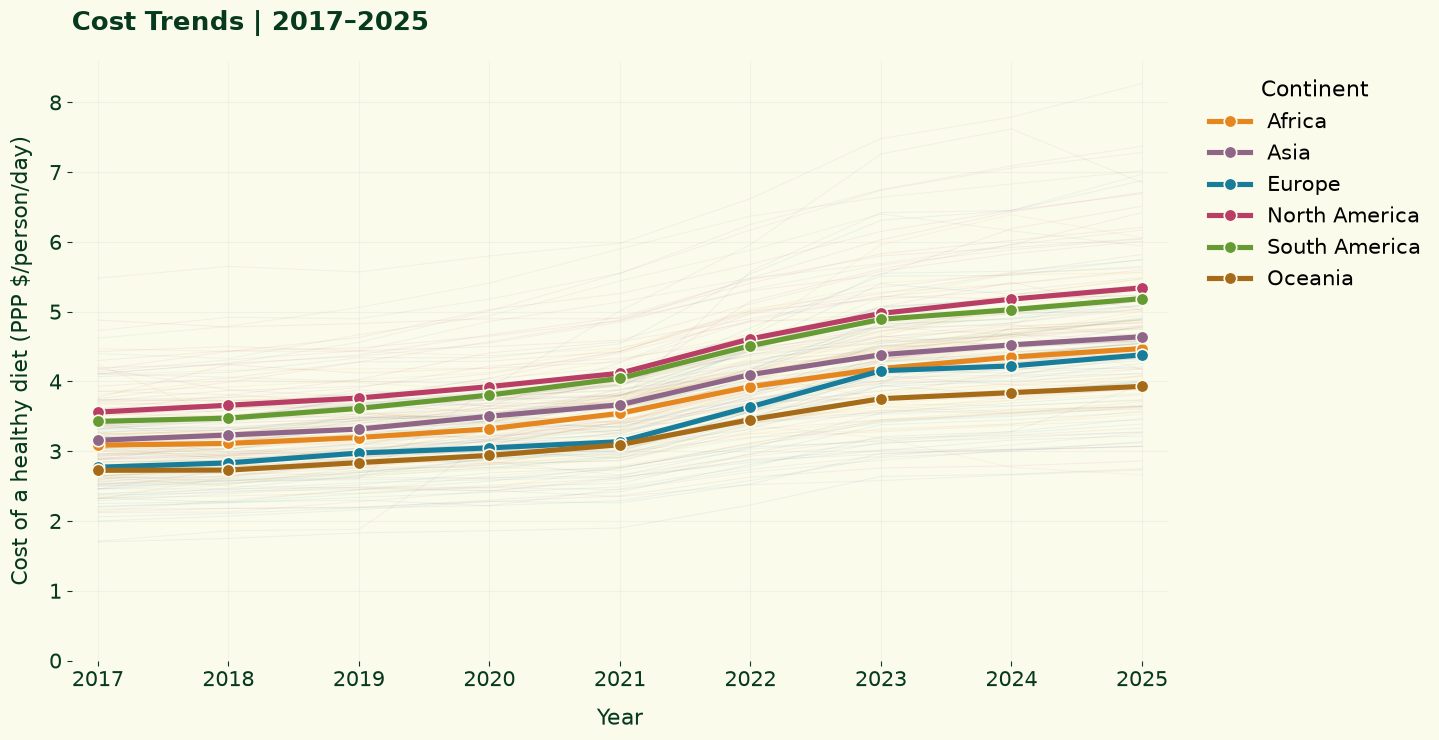

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/3.2_continent_cohd_trends_2017_2025.png
Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/3.3_cohd_change_vs_pua_change.png


In [11]:
eda.plot_continent_time_trends(df, 'PUA', 'Affordability Trends | 2017–2025', '3.1_continent_pua_trends_2017_2025.png')
eda.plot_continent_time_trends(df, 'CoHD', 'Cost Trends | 2017–2025', '3.2_continent_cohd_trends_2017_2025.png')
eda.plot_cost_vs_affordability_changes(df)

### RQ4. What is behind the price of a healthy diet?
The six food groups are available for 2021. We compare their costs and continental composition and examine the descriptive association between total cost and PUA.

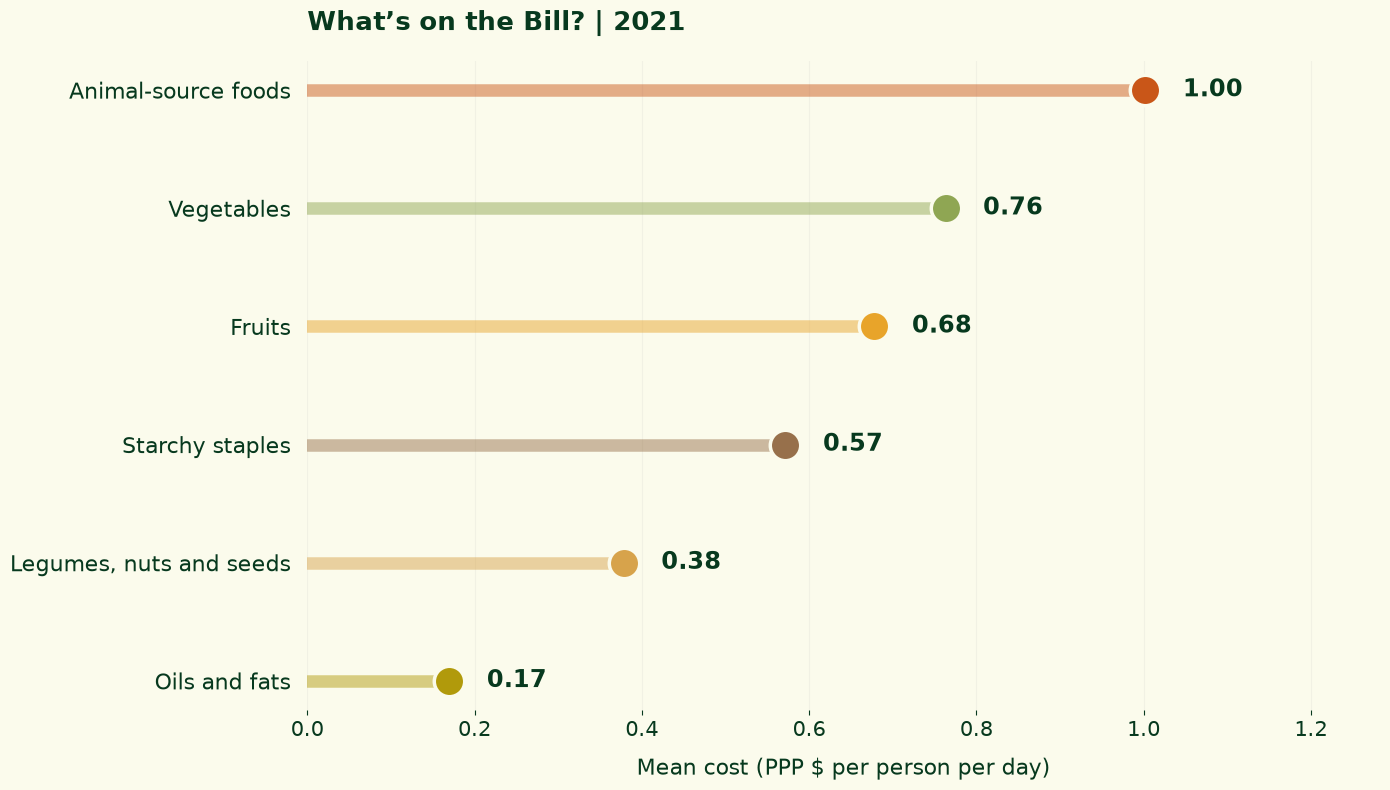

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/4.1_food_category_costs_2021.png
4.1: complete countries: 161


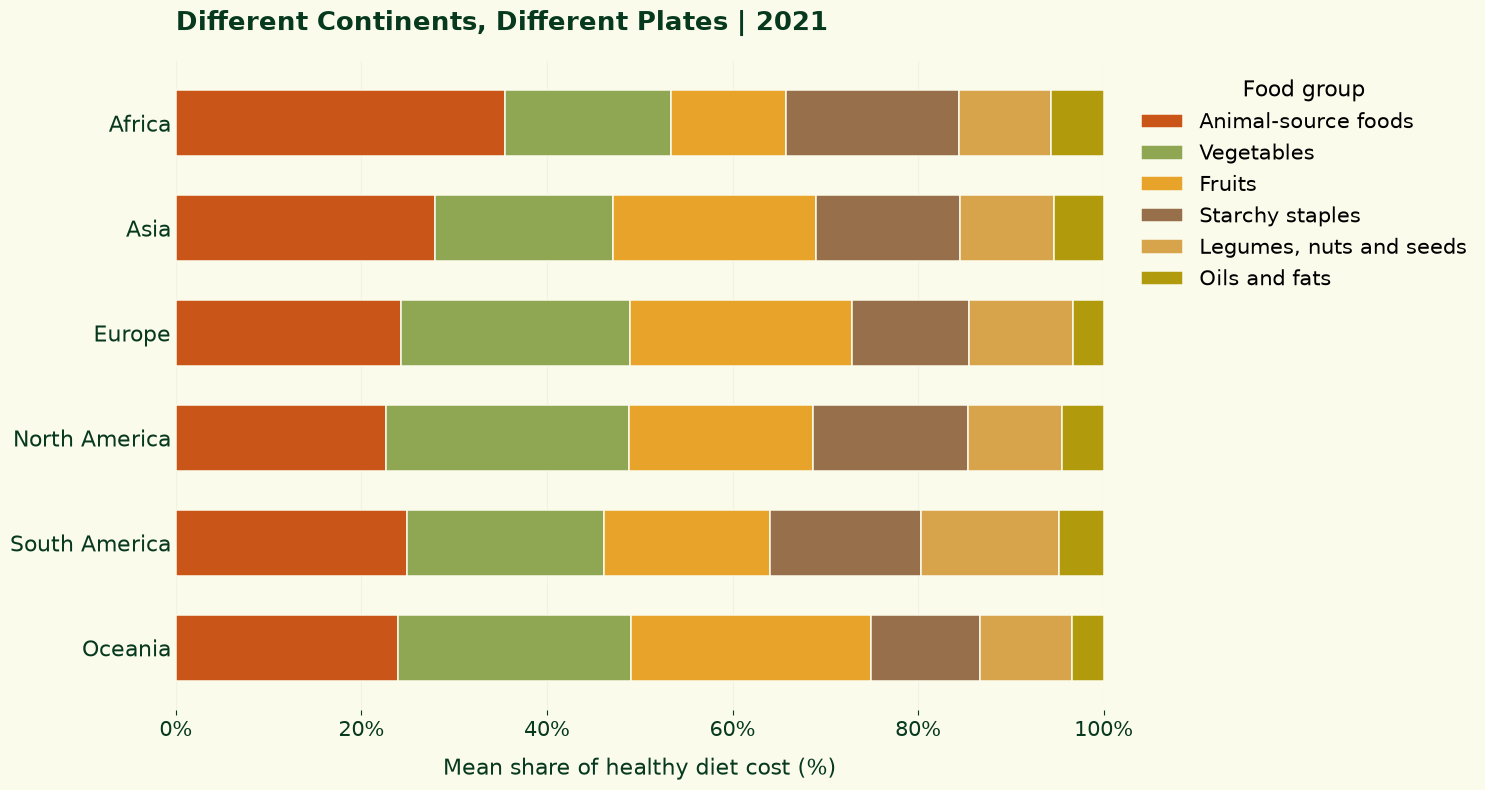

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/4.2_food_cost_composition_by_continent_2021.png
4.2: complete countries: 161


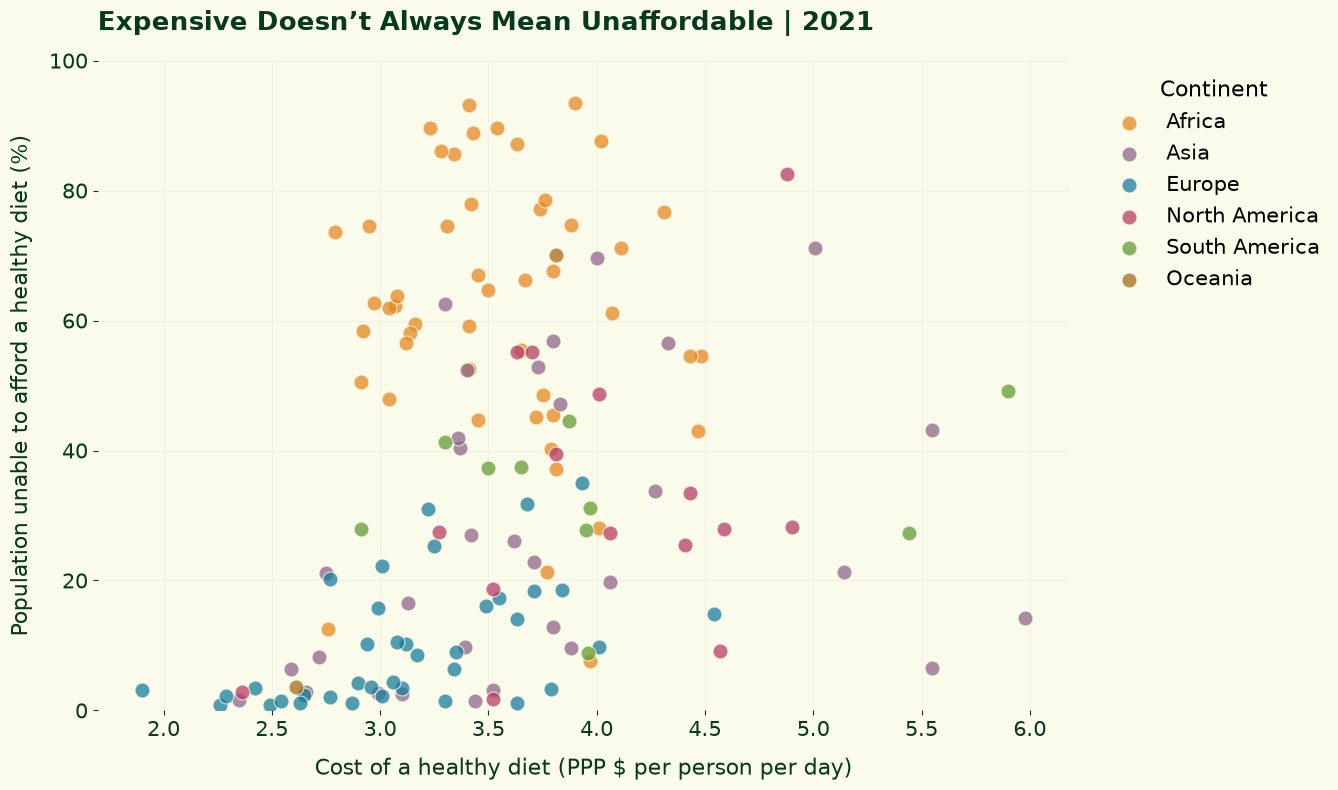

Saved: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/02_eda/figures/4.3_cohd_vs_pua_2021.png


In [12]:
eda.create_food_cost_charts(df, food_data=food_2021)

## 5. Data preprocessing for machine learning

The two tasks require different datasets. **Unsupervised learning** uses a single year (2021), retaining complete cases for the prepared clustering features. **Supervised learning** uses the longitudinal panel and keeps observations with observed PUA. Missing predictors are handled inside training pipelines, avoiding leakage from future years. Outliers are reported rather than automatically removed.

In [13]:
panel_prepared = preprocessing.prepare_panel(panel)
missing_report = preprocessing.create_missing_value_report(panel_prepared, ['PUA'] + preprocessing.SUPERVISED_FEATURES)
outlier_report = preprocessing.create_outlier_report(panel_prepared, ['PUA'] + preprocessing.SUPERVISED_FEATURES)
print('Missing values:')
display(missing_report)
print('Outlier report:')
display(outlier_report)
unsupervised_all, unsupervised = preprocessing.prepare_unsupervised_data(panel_prepared)
supervised = preprocessing.prepare_supervised_data(panel_prepared)
summary = preprocessing.save_preprocessing_results(panel_prepared, unsupervised_all, unsupervised, supervised)
display(summary)
print('Clustering sample:', len(unsupervised), 'countries')
print('Supervised sample:', len(supervised), 'country-year rows')

Missing values:


,variable,missing_n,missing_pct
0,PUA,245,15.74
1,CoHD,74,4.75
2,GDP_PPP,29,1.86
3,Urban,0,0.00
4,Unemployment,109,7.00
5,Inflation,101,6.49
6,Population_Density,4,0.26


Outlier report:


,variable,n,q1,q3,lower_iqr,upper_iqr,outliers_iqr
0,PUA,1312,9.400000,56.625000,-61.437500,127.462500,0
1,CoHD,1483,3.080000,4.390000,1.115000,6.355000,30
2,GDP_PPP,1528,6502.286314,41197.124385,-45539.970793,93239.381492,44
3,Urban,1557,43.444908,78.814642,-9.609693,131.869243,0
4,Unemployment,1448,3.522000,9.298750,-5.143125,17.963875,107
5,Inflation,1456,1.648611,6.742394,-5.992063,14.383068,136
6,Population_Density,1553,32.959460,206.204521,-226.908132,466.072112,112


,dataset,rows,countries
0,panel_original,1557,173
1,unsupervised_2021,151,151
2,supervised_panel,1312,146


Clustering sample: 151 countries
Supervised sample: 1312 country-year rows


## 6. Unsupervised learning — PCA and K-Means

**Question:** Can we identify groups of countries with similar socioeconomic characteristics?

The implemented clustering uses **four features**: `log_GDP_PPP`, `Urban`, `Unemployment`, and `Inflation`. Inflation is signed-log transformed and features are standardized. PCA summarizes variation and provides a two-dimensional view. K-Means is evaluated for **K = 2,…,8** using the silhouette score. **CoHD and PUA are not clustering inputs**: they are used to interpret the resulting groups.

**Methodological note:** the preprocessing dataset also prepares CoHD as a complete-case criterion, even though the clustering itself uses only the four socioeconomic features. This reproduces the current scripts; changing it would change the sample and possibly the results.

In [14]:
unsup.ensure_output_directories()
cluster_input, cluster_x, cluster_z = unsup.prepare_features(unsupervised, unsup.ECON_FEATURES)
print('Features used:', unsup.ECON_FEATURES)
print('Standardized observations:', cluster_z.shape)
display(cluster_input.head())

Features used: ['log_GDP_PPP', 'Urban', 'Unemployment', 'Inflation']
Standardized observations: (151, 4)


,ISO3,Country,Continent,Year,CoHD,GDP_PPP,Urban,Unemployment,Inflation,PUA,log_GDP_PPP
0,ALB,Albania,Europe,2021,3.49,18212.794718,57.507719,11.474,2.041472,16.0,9.809880
1,DZA,Algeria,Africa,2021,4.47,14496.865470,73.619922,13.656,7.226063,43.0,9.581688
2,AGO,Angola,Africa,2021,4.11,8720.187687,68.252416,15.799,25.754295,71.1,9.073396
3,ARM,Armenia,Asia,2021,3.80,15921.705282,65.357288,15.469,7.184836,56.8,9.675439
4,AUS,Australia,Oceania,2021,2.61,58327.414684,87.235341,5.022,2.863913,3.6,10.973827


In [15]:
pca_coordinates, explained_variance = unsup.pca_analysis(cluster_input, cluster_z, unsup.ECON_FEATURES, 'economic')
print('Explained variance:', explained_variance)
cluster_assignments = unsup.run_clustering(cluster_input, cluster_x, cluster_z, pca_coordinates, explained_variance, 'economic')
display(cluster_assignments.head())
display(cluster_assignments.groupby('Cluster').agg(countries=('ISO3','count'), median_CoHD=('CoHD','median'), median_PUA=('PUA','median')))


=== PCA EXPLAINED VARIANCE ===
PC1: 45.27% | Cumulative: 45.27%
PC2: 26.05% | Cumulative: 71.32%
PC3: 22.40% | Cumulative: 93.72%
PC4: 6.28% | Cumulative: 100.00%

PC1 + PC2: 71.32%
Explained variance: [0.45267971 0.26052229 0.22398936 0.06280864]

=== K SELECTION ===
 k    inertia  silhouette
 2 409.336975    0.320974
 3 301.370663    0.351023
 4 252.263541    0.332202
 5 223.153375    0.279070
 6 197.367268    0.280102
 7 178.660364    0.236866
 8 161.666696    0.236320

Selected K: 3

=== PCA SCATTERPLOTS ===
PC1-PC2: 71.32% explained variance
PC2-PC3: 48.45% explained variance
PC1-PC3: 67.67% explained variance

Saved 3 PCA scatterplots.

=== K-MEANS RESULTS ===
Countries analyzed: 151
Number of clusters: 3
Silhouette Score: 0.351

Cluster sizes:
 Cluster  countries
       1         66
       2         35
       3         50


,ISO3,Country,Continent,CoHD,PUA,Cluster
0,ALB,Albania,Europe,3.49,16.0,2
1,DZA,Algeria,Africa,4.47,43.0,2
2,AGO,Angola,Africa,4.11,71.1,2
3,ARM,Armenia,Asia,3.80,56.8,2
4,AUS,Australia,Oceania,2.61,3.6,1


,countries,median_CoHD,median_PUA
Cluster,,,
1,66,3.15,6.5
2,35,3.75,38.8
3,50,3.51,56.6


### Cluster interpretation and geographic distribution

The heatmap compares standardized socioeconomic profiles. The world map shows where clusters are located. Notched boxplots compare CoHD and PUA **after** clustering, to describe differences between groups rather than to define them.

In [16]:
unsup.cluster_heatmap(cluster_z, unsup.ECON_FEATURES, cluster_assignments, 'economic')
unsup.world_cluster_map(cluster_assignments, 'economic', all_countries=unsupervised_all)
for target in ('CoHD','PUA'):
    display(cluster_assignments.groupby('Cluster')[target].agg(['count','mean','median','std']).round(2))
print('Additional original cluster comparison plots can be generated by the complete analysis call below.')


=== WORLD MAP ===
Countries with clusters: 151
Countries without clusters: 22


,count,mean,median,std
Cluster,,,,
1,66,3.31,3.15,0.80
2,35,3.85,3.75,0.72
3,50,3.61,3.51,0.50


,count,mean,median,std
Cluster,,,,
1,57,14.34,6.5,15.26
2,34,37.39,38.8,23.02
3,49,55.07,56.6,23.11


Additional original cluster comparison plots can be generated by the complete analysis call below.


In [17]:
# Reproduce all original cluster comparison figures (including notched boxplots).
# This repeats the PCA/K-Means fitting already shown above, using the same inputs and parameters.
unsupervised_results = unsup.run_unsupervised_analysis(
    unsupervised_data=unsupervised,
    all_countries=unsupervised_all,
)
assert len(unsupervised_results['cluster_assignments']) == len(unsupervised)


=== 2021 SOCIOECONOMIC CLUSTERING ===

=== PCA EXPLAINED VARIANCE ===
PC1: 45.27% | Cumulative: 45.27%
PC2: 26.05% | Cumulative: 71.32%
PC3: 22.40% | Cumulative: 93.72%
PC4: 6.28% | Cumulative: 100.00%

PC1 + PC2: 71.32%

=== K SELECTION ===
 k    inertia  silhouette
 2 409.336975    0.320974
 3 301.370663    0.351023
 4 252.263541    0.332202
 5 223.153375    0.279070
 6 197.367268    0.280102
 7 178.660364    0.236866
 8 161.666696    0.236320

Selected K: 3

=== PCA SCATTERPLOTS ===
PC1-PC2: 71.32% explained variance
PC2-PC3: 48.45% explained variance
PC1-PC3: 67.67% explained variance

Saved 3 PCA scatterplots.

=== K-MEANS RESULTS ===
Countries analyzed: 151
Number of clusters: 3
Silhouette Score: 0.351

Cluster sizes:
 Cluster  countries
       1         66
       2         35
       3         50

=== WORLD MAP ===
Countries with clusters: 151
Countries without clusters: 22

=== CoHD BY CLUSTER ===
         count  mean  median   std
Cluster                           
1          

## 7. Supervised learning — predicting PUA

**Question:** Can socioeconomic indicators predict the share of people who cannot afford a healthy diet?

The target is **PUA**. The models use log GDP PPP, urbanization, unemployment, inflation and population density; Random Forest is also compared with and without continent. We use a **temporal split**: training 2017–2022, validation 2023, test 2024–2025. Dummy Regressor, Linear Regression and Random Forest are compared on validation data. The final Random Forest with continent is refitted on training + validation and evaluated on the held-out test period. MAE, RMSE and R² measure predictive accuracy. Permutation importance and partial dependence help interpret the fitted model, but they do not establish causal effects.

In [18]:
print('Target: PUA')
print('Numerical predictors:', sup.NUMERIC)
print('With continent:', sup.AUGMENTED)
display(supervised.groupby('Year').agg(rows=('PUA','size'), countries=('ISO3','nunique')))

Target: PUA
Numerical predictors: ['log_GDP_PPP', 'Urban', 'Unemployment', 'Inflation', 'Population_Density']
With continent: ['log_GDP_PPP', 'Urban', 'Unemployment', 'Inflation', 'Population_Density', 'Continent']


,rows,countries
Year,,
2017,146,146
2018,146,146
2019,146,146
2020,146,146
2021,146,146
2022,146,146
2023,146,146
2024,145,145
2025,145,145


In [19]:
supervised_results = sup.run_supervised_analysis(supervised_data=supervised)
print('Random Forest feature-set comparison — validation 2023:')
display(supervised_results['validation'])
print('Dummy vs Linear Regression vs Random Forest — validation 2023:')
display(supervised_results['model_comparison'])
print('Final model — test 2024–2025:')
display(pd.DataFrame([supervised_results['test_metrics']]))
print('Permutation importance:')
display(supervised_results['permutation_importance'])
print('Sample predictions:')
display(supervised_results['test_predictions'].head())

Train: 876; validation: 146; test: 290

Validation 2023:
                    model    MAE    RMSE     R2
            Socioeconomic 7.6526 11.2696 0.8355
Socioeconomic + Continent 6.5705 10.3917 0.8602

Model Comparison — Validation 2023:
            model     MAE    RMSE      R2
  Dummy Regressor 24.4910 27.8045 -0.0011
Linear Regression 11.2243 14.8050  0.7162
    Random Forest  6.5705 10.3917  0.8602
Selected by validation MAE: Random Forest

Final test 2024–2025 (with Continent):
   MAE   RMSE     R2
6.5361 9.7902 0.8754

Permutation importance:
           feature  MAE_increase   std
       log_GDP_PPP        11.093 0.602
         Continent         7.051 0.558
             Urban         4.324 0.183
Population_Density         2.382 0.234
      Unemployment         1.346 0.123
         Inflation         0.453 0.086

Saved outputs under: /Users/giorgia/Desktop/healthy_eating_analisys/outputs/05_supervised
All figures and tables generated by the analysis function.
Interpret associations

,model,MAE,RMSE,R2
0,Socioeconomic,7.652648,11.269630,0.835530
1,Socioeconomic + Continent,6.570533,10.391686,0.860157


Dummy vs Linear Regression vs Random Forest — validation 2023:


,model,MAE,RMSE,R2
0,Dummy Regressor,24.490974,27.804456,-0.001144
1,Linear Regression,11.224279,14.804972,0.716154
2,Random Forest,6.570533,10.391686,0.860157


Final model — test 2024–2025:


,MAE,RMSE,R2
0,6.536082,9.790203,0.875443


Permutation importance:


,feature,MAE_increase,std
0,log_GDP_PPP,11.092936,0.602282
5,Continent,7.050635,0.558386
1,Urban,4.324320,0.183484
4,Population_Density,2.382495,0.234352
2,Unemployment,1.345896,0.123033
3,Inflation,0.453401,0.085809


Sample predictions:


,ISO3,Country,Continent,Year,PUA,Predicted_PUA,Residual,Absolute_Error
1022,AGO,Angola,Africa,2024,72.2,62.379692,9.820308,9.820308
1023,ALB,Albania,Europe,2024,12.6,21.849579,-9.249579,9.249579
1024,ARE,United Arab Emirates,Asia,2024,2.0,2.420204,-0.420204,0.420204
1025,ARM,Armenia,Asia,2024,46.6,27.933768,18.666232,18.666232
1026,AUS,Australia,Oceania,2024,3.2,2.713882,0.486118,0.486118
